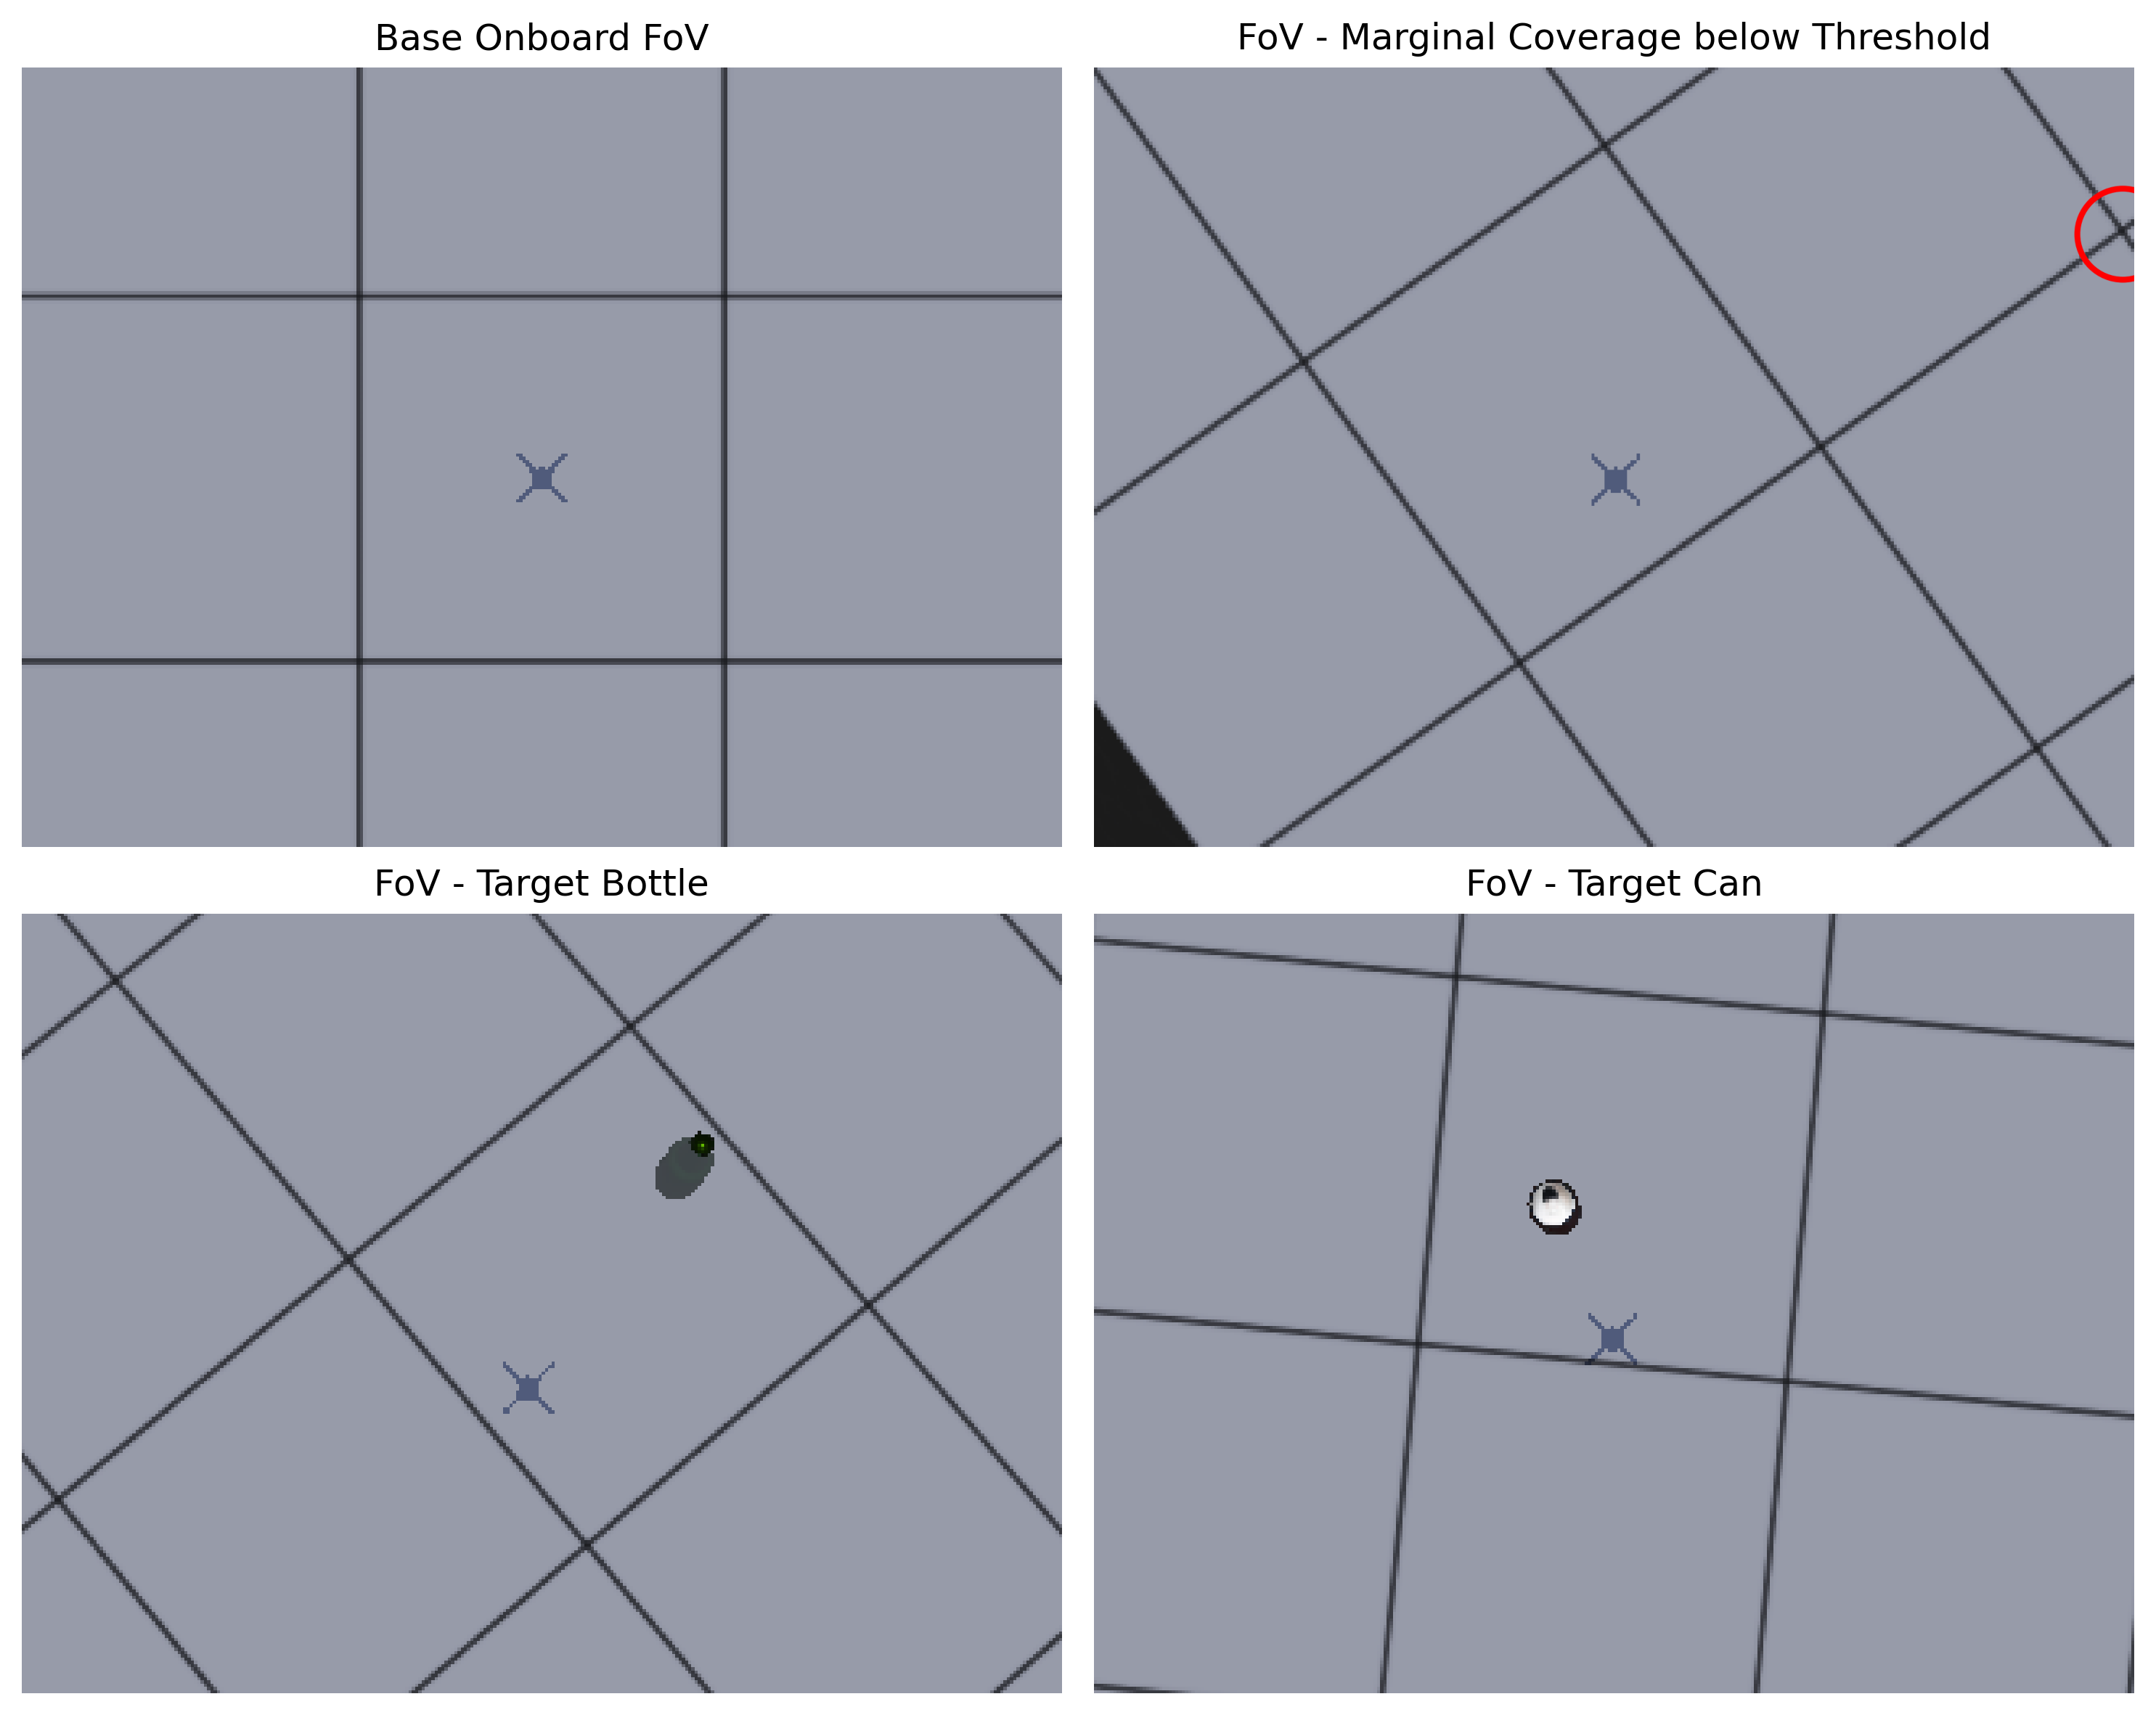

Saved figure to: capture_visuals_thesis/thesis_2x2_image_grid.png


In [7]:
# Cell 1 — 2x2 image grid from four filepaths

from pathlib import Path
import matplotlib.pyplot as plt
from PIL import Image

# Replace these with your four image paths
image_paths = [
    "../logs/log_run_aif_saccade_table_captures_tesi/captures/drone_fov_base.png",
    "../logs/log_run_aif_saccade_table_captures_tesi/captures/drone_fov_marginal_cov_annotated.png",
    "../logs/log_run_aif_saccade_table_captures_tesi/captures/drone_fov_base_bottle.png",
    "../logs/log_run_aif_saccade_table_captures_tesi/captures/drone_fov_base_can.png",
]

titles = [
    "Base Onboard FoV",
    "FoV - Marginal Coverage below Threshold",
    "FoV - Target Bottle",
    "FoV - Target Can",
]

save_dir = Path("capture_visuals_thesis")

fig, axes = plt.subplots(2, 2, figsize=(10, 8), dpi=300)

for ax, img_path, title in zip(axes.ravel(), image_paths, titles):
    img = Image.open(img_path)
    ax.imshow(img)
    ax.set_title(title, fontsize=12)
    ax.axis("off")

plt.tight_layout()

out_path = save_dir / "thesis_2x2_image_grid.png"
plt.savefig(out_path, bbox_inches="tight", dpi=300)
plt.show()

print(f"Saved figure to: {out_path}")

In [8]:
# Cell 2 — same figure saved as PDF too

fig.savefig(save_dir / "thesis_2x2_image_grid.pdf", bbox_inches="tight", dpi=300)


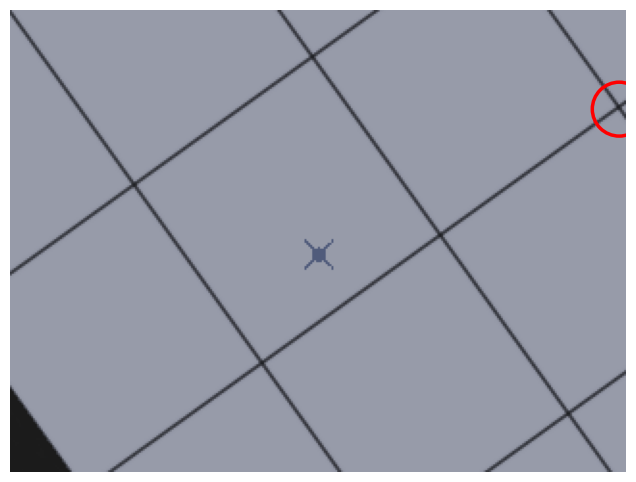

In [6]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle

# Paste your image path here
IMAGE_PATH = Path("../logs/log_run_aif_saccade_table_captures_tesi/captures/drone_fov_marginal_cov.png")

# Choose: "circle" or "rectangle"
SHAPE = "circle"

# The tiny visible cell fragment at the upper-right edge
CENTER_XY = (316, 51)      # pixel coordinates: (x, y)
CIRCLE_RADIUS = 14         # pixels

# Used only when SHAPE == "rectangle"
RECT_XY = (302, 39)        # top-left corner: (x, y)
RECT_WIDTH = 18
RECT_HEIGHT = 28

# Optional: set to a path such as "fov_marginal_coverage_annotated.png"
OUTPUT_PATH = "fov_marginal_coverage_annotated.png"

image = Image.open(IMAGE_PATH).convert("RGB")

fig, ax = plt.subplots(figsize=(8, 6))
ax.imshow(image)

if SHAPE == "circle":
    annotation = Circle(
        CENTER_XY,
        radius=CIRCLE_RADIUS,
        fill=False,
        edgecolor="red",
        linewidth=2.5,
    )
elif SHAPE == "rectangle":
    annotation = Rectangle(
        RECT_XY,
        width=RECT_WIDTH,
        height=RECT_HEIGHT,
        fill=False,
        edgecolor="red",
        linewidth=2.5,
    )
else:
    raise ValueError("SHAPE must be either 'circle' or 'rectangle'.")

ax.add_patch(annotation)
ax.axis("off")

if OUTPUT_PATH is not None:
    fig.savefig(OUTPUT_PATH, dpi=300, bbox_inches="tight", pad_inches=0)

plt.show()

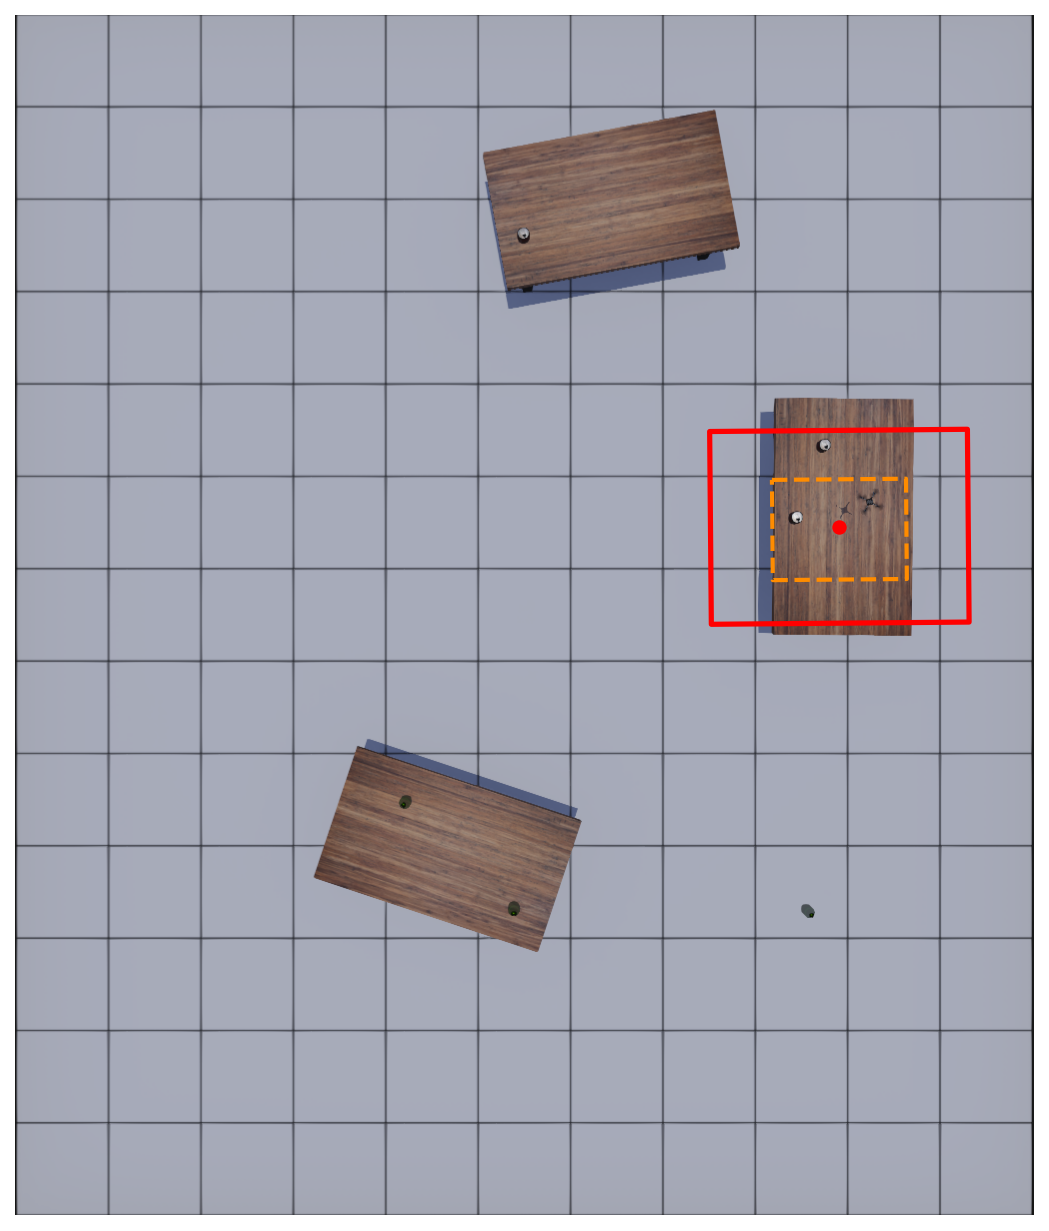

In [19]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from PIL import Image

# =============================================================================
# INPUTS TO EDIT
# =============================================================================

VIEWS = [
    {
        "path": Path("../logs/log_run_aif_saccade_table_captures_tesi/captures/world_screenshot_table_can.png"),
        "drone_xy": (1.622, 0.53),   # Webots/world coordinates in metres
        "yaw_deg": 0.5,
        "name": "top_down_view",

        # Pixel coordinates of the room/grid boundaries:
        # (left, top, right, bottom)
        #
        # For the uploaded screenshot, use this as the initial calibration.
        "room_pixel_bounds": (16, 16, 1033, 1214),
    },
]

# Toggle OFF for final exported figures.
SHOW_REFERENCE_DOT = True

# Use "drone" while calibrating x,y alignment.
# Use "fov_center" only when you want to show the centre of the drawn footprint.
DOT_LOCATION = "fov_center"   # "drone" or "fov_center"

# Required yaw correction from the previous iteration.
YAW_OFFSET_DEG = 90.0

# -------------------------------------------------------------------------
# Optional fixed camera/FoV-anchor correction.
#
# Only adjust this if, AFTER setting room_pixel_bounds correctly, there is
# still a consistent offset between the physical drone position and the
# drawn FoV across all screenshots.
#
# Convention: (forward_offset_m, left_offset_m), in the drone body frame.
# Keep (0.0, 0.0) unless a persistent offset remains.
# -------------------------------------------------------------------------
FOV_ANCHOR_OFFSET_BODY_M = (0.0, 0.0)

# -------------------------------------------------------------------------
# Room / world coordinates
# -------------------------------------------------------------------------
MIN_X, MAX_X = -2.75, 2.75
MIN_Y, MAX_Y = -3.25, 3.25
WORLD_Y_POINTS_UP = True

# -------------------------------------------------------------------------
# Floor-plane FoV: copied from crazyflie_AIF.py
# -------------------------------------------------------------------------
FLYING_ATTITUDE_M = 1.5

FOV_WIDTH_M = 1.394
FOV_FORWARD_M = 0.553
FOV_BACKWARD_M = 0.493

# -------------------------------------------------------------------------
# Optional table-height FoV overlay
#
# This reproduces the controller's height-aware scaling:
# scale = (camera_height - table_height) / camera_height
# -------------------------------------------------------------------------
SHOW_TABLE_HEIGHT_FOV = True

FLOOR_HEIGHT_M = 0.0
TABLE_HEIGHT_M = 0.72

FLOOR_FOV_COLOR = "red"
TABLE_FOV_COLOR = "darkorange"

FLOOR_FOV_LINEWIDTH = 2.5
TABLE_FOV_LINEWIDTH = 2.0
TABLE_FOV_LINESTYLE = "--"

DOT_SIZE = 35
FIG_DPI = 150

OUTPUT_DIR = Path("annotated_top_down_views")


# =============================================================================
# GEOMETRY HELPERS
# =============================================================================

def world_to_pixel(x, y, image_width, image_height, room_pixel_bounds):
    """Convert room/world coordinates to image pixel coordinates."""
    left, top, right, bottom = room_pixel_bounds

    u = left + (x - MIN_X) / (MAX_X - MIN_X) * (right - left)

    y_fraction = (y - MIN_Y) / (MAX_Y - MIN_Y)
    if WORLD_Y_POINTS_UP:
        v = bottom - y_fraction * (bottom - top)
    else:
        v = top + y_fraction * (bottom - top)

    return np.array([u, v], dtype=float)


def body_offset_to_world(drone_x, drone_y, yaw_deg, forward_offset_m, left_offset_m):
    """Apply a body-frame offset to the drone position."""
    yaw = np.deg2rad(yaw_deg)

    forward = np.array([np.cos(yaw), np.sin(yaw)])
    left = np.array([-np.sin(yaw), np.cos(yaw)])

    anchor = (
        np.array([drone_x, drone_y], dtype=float)
        + float(forward_offset_m) * forward
        + float(left_offset_m) * left
    )
    return anchor


def fov_world_corners(anchor_xy, yaw_deg, *, width_m, forward_m, backward_m):
    """Return the four footprint corners in clockwise world-coordinate order."""
    yaw = np.deg2rad(yaw_deg)

    forward = np.array([np.cos(yaw), np.sin(yaw)])
    left = np.array([-np.sin(yaw), np.cos(yaw)])

    anchor = np.asarray(anchor_xy, dtype=float)
    half_width = float(width_m) / 2.0

    front_left = anchor + float(forward_m) * forward + half_width * left
    front_right = anchor + float(forward_m) * forward - half_width * left
    rear_right = anchor - float(backward_m) * forward - half_width * left
    rear_left = anchor - float(backward_m) * forward + half_width * left

    return np.array([front_left, front_right, rear_right, rear_left])


def add_fov_outline(
    ax,
    corners_world,
    *,
    image_width,
    image_height,
    room_pixel_bounds,
    color,
    linewidth,
    linestyle="-",
):
    corners_px = np.array(
        [
            world_to_pixel(
                x, y,
                image_width,
                image_height,
                room_pixel_bounds,
            )
            for x, y in corners_world
        ]
    )

    patch = Polygon(
        corners_px,
        closed=True,
        fill=False,
        edgecolor=color,
        linewidth=linewidth,
        linestyle=linestyle,
        joinstyle="round",
    )
    ax.add_patch(patch)
    return corners_world.mean(axis=0)


# =============================================================================
# DRAW OVERLAYS
# =============================================================================

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
rendered_figures = []

table_fov_scale = (
    (FLYING_ATTITUDE_M - TABLE_HEIGHT_M)
    / (FLYING_ATTITUDE_M - FLOOR_HEIGHT_M)
)

for view in VIEWS:
    image_path = Path(view["path"])
    image = Image.open(image_path).convert("RGB")
    image_width, image_height = image.size

    drone_x, drone_y = map(float, view["drone_xy"])
    effective_yaw_deg = float(view["yaw_deg"]) + YAW_OFFSET_DEG
    room_pixel_bounds = view["room_pixel_bounds"]
    name = view.get("name", image_path.stem)

    # Apply any fixed GPS-to-camera/FoV anchor offset.
    fov_anchor_xy = body_offset_to_world(
        drone_x,
        drone_y,
        effective_yaw_deg,
        FOV_ANCHOR_OFFSET_BODY_M[0],
        FOV_ANCHOR_OFFSET_BODY_M[1],
    )

    # Full floor-plane projection.
    floor_corners_world = fov_world_corners(
        fov_anchor_xy,
        effective_yaw_deg,
        width_m=FOV_WIDTH_M,
        forward_m=FOV_FORWARD_M,
        backward_m=FOV_BACKWARD_M,
    )

    fig, ax = plt.subplots(
        figsize=(image_width / FIG_DPI, image_height / FIG_DPI),
        dpi=FIG_DPI,
    )
    fig.subplots_adjust(left=0, right=1, bottom=0, top=1)

    ax.imshow(image)
    ax.set_xlim(0, image_width)
    ax.set_ylim(image_height, 0)
    ax.axis("off")

    floor_center_world = add_fov_outline(
        ax,
        floor_corners_world,
        image_width=image_width,
        image_height=image_height,
        room_pixel_bounds=room_pixel_bounds,
        color=FLOOR_FOV_COLOR,
        linewidth=FLOOR_FOV_LINEWIDTH,
    )

    # Smaller projection at table height.
    if SHOW_TABLE_HEIGHT_FOV:
        table_corners_world = fov_world_corners(
            fov_anchor_xy,
            effective_yaw_deg,
            width_m=FOV_WIDTH_M * table_fov_scale,
            forward_m=FOV_FORWARD_M * table_fov_scale,
            backward_m=FOV_BACKWARD_M * table_fov_scale,
        )

        add_fov_outline(
            ax,
            table_corners_world,
            image_width=image_width,
            image_height=image_height,
            room_pixel_bounds=room_pixel_bounds,
            color=TABLE_FOV_COLOR,
            linewidth=TABLE_FOV_LINEWIDTH,
            linestyle=TABLE_FOV_LINESTYLE,
        )

    if SHOW_REFERENCE_DOT:
        if DOT_LOCATION == "drone":
            dot_world = np.array([drone_x, drone_y], dtype=float)

        elif DOT_LOCATION == "fov_center":
            dot_world = floor_center_world

        else:
            raise ValueError("DOT_LOCATION must be 'drone' or 'fov_center'.")

        dot_px = world_to_pixel(
            dot_world[0],
            dot_world[1],
            image_width,
            image_height,
            room_pixel_bounds,
        )

        ax.scatter(
            dot_px[0],
            dot_px[1],
            s=DOT_SIZE,
            c="red",
            zorder=10,
        )

    pdf_path = OUTPUT_DIR / f"{name}_fov.pdf"
    rendered_figures.append((fig, pdf_path))

    plt.show()

In [13]:
[fig.savefig(pdf_path, format="pdf", dpi=FIG_DPI) for fig, pdf_path in rendered_figures]

[None]

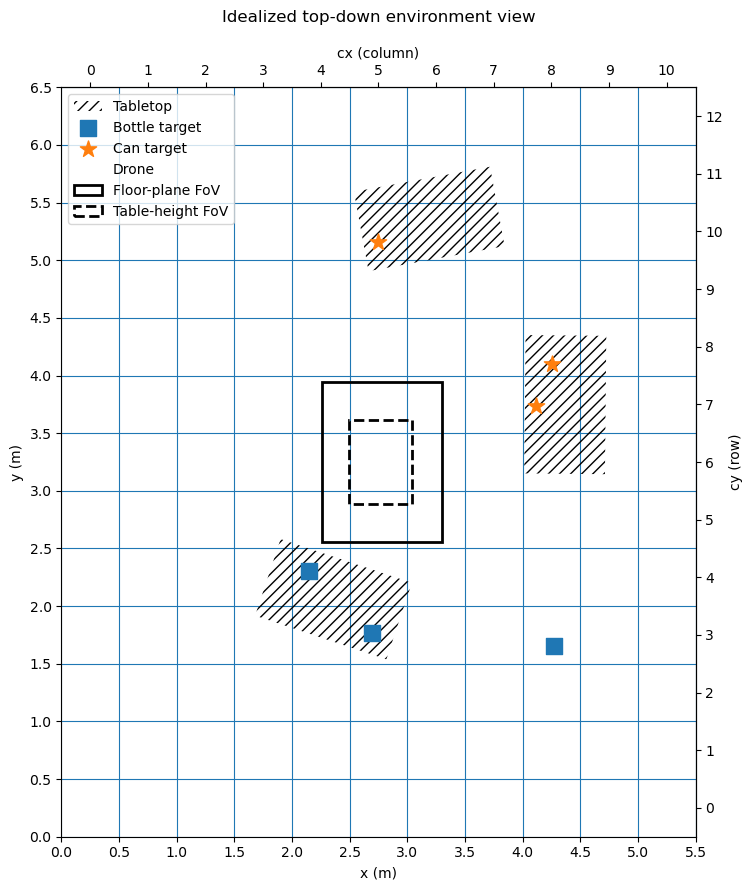

In [ ]:
from pathlib import Path
import json
import math

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon


# =============================================================================
# INPUTS / TOGGLES
# =============================================================================

# Paste the supervisor-generated manifest path here.
JSON_PATH = Path("../../shared/spawned_objects.json")

# Room and grid configuration.
ROOM_WIDTH_M = 5.5
ROOM_HEIGHT_M = 6.5
CELL_SIZE_M = 0.5

# Webots/world coordinates of the room bounds.
WORLD_MIN_X = -ROOM_WIDTH_M / 2.0
WORLD_MIN_Y = -ROOM_HEIGHT_M / 2.0

GRID_COLS = int(ROOM_WIDTH_M / CELL_SIZE_M)   # 11
GRID_ROWS = int(ROOM_HEIGHT_M / CELL_SIZE_M)  # 13

# -------------------------------------------------------------------------
# Visibility toggles
# -------------------------------------------------------------------------
SHOW_GRID = True
SHOW_TABLES = True
SHOW_TARGETS = True
SHOW_DRONE = True
SHOW_FLOOR_FOV = True
SHOW_TABLE_HEIGHT_FOV = True
SHOW_LEGEND = True
SHOW_OBJECT_LABELS = False

# Axis layout:
#   "meters_primary" -> bottom/left: metres, top/right: grid coordinates
#   "cells_primary"  -> bottom/left: grid coordinates, top/right: metres
AXIS_MODE = "meters_primary"

TITLE = "Idealized top-down environment view"

# -------------------------------------------------------------------------
# Drone configuration
#
# Set DRONE_COORDINATE_FRAME to:
#   "world" -> use the same coordinates reported by Webots/controller GPS
#   "room"  -> use room-local metres: x in [0, 5.5], y in [0, 6.5]
# -------------------------------------------------------------------------
DRONE_COORDINATE_FRAME = "world"

DRONE_X = 0.0
DRONE_Y = 0.0
DRONE_YAW_RAD = 0.0      # Controller/Webots yaw: 0 rad points along +x

# Optional fixed camera-anchor offset in the drone body frame.
# Keep at (0.0, 0.0) unless you explicitly want to model one.
# Convention: (forward_offset_m, left_offset_m)
CAMERA_ANCHOR_OFFSET_BODY_M = (0.0, 0.0)

# -------------------------------------------------------------------------
# FoV geometry: copied from crazyflie_AIF.py
# -------------------------------------------------------------------------
FLYING_ATTITUDE_M = 1.5
TABLE_HEIGHT_M = 0.72

FOV_WIDTH_M = 1.394
FOV_FORWARD_M = 0.553
FOV_BACKWARD_M = 0.493

FOV_LINEWIDTH = 2.0
TABLE_FOV_LINESTYLE = "--"

# -------------------------------------------------------------------------
# Visual sizing
# -------------------------------------------------------------------------
TABLE_HATCH = "///"

TABLE_SURFACE_COLOR = "#8B5A2B"

BOTTLE_COLOR = "#84CC16"
BOTTLE_EDGE_COLOR = "#3F6212"

CAN_COLOR = "#F97316"
CAN_EDGE_COLOR = "#9A3412"

DRONE_FACE_COLOR = "#7E57C2"
DRONE_EDGE_COLOR = "#3C1E6E"

DIRECT_TABLE_CELL_COLOR = "#4C9BE8"
TRANSIENT_FLOOR_CELL_COLOR = "#F39C12"

TABLE_DETECTION_BBOX_COLOR = "#6B7280"
TABLE_DETECTION_BBOX_LINESTYLE = (0, (3, 2))

DIRECT_TABLE_ALPHA = 0.32
TRANSIENT_FLOOR_ALPHA = 0.32

FOV_COLOR = "black"
FOV_LINEWIDTH = 2.0

TARGET_MARKER_SIZE = 110
DRONE_SIZE_M = 0.17

SHOW_TABLE_DETECTION_BBOX = True

FIGSIZE = (8.0, 9.0)
SAVE_PATH = "../annotated_top_down_views/env_schema_tables.pdf"
# Example:
# SAVE_PATH = Path("idealized_environment_view.pdf")


# =============================================================================
# HELPERS
# =============================================================================

def world_to_room_xy(x, y):
    """Convert centered Webots world coordinates to room-local metres."""
    return np.array(
        [
            float(x) - WORLD_MIN_X,
            float(y) - WORLD_MIN_Y,
        ],
        dtype=float,
    )


def drone_input_to_world_xy(x, y):
    """Interpret manual drone coordinates in either world or room-local units."""
    if DRONE_COORDINATE_FRAME == "world":
        return np.array([float(x), float(y)], dtype=float)

    if DRONE_COORDINATE_FRAME == "room":
        return np.array(
            [
                float(x) + WORLD_MIN_X,
                float(y) + WORLD_MIN_Y,
            ],
            dtype=float,
        )

    raise ValueError("DRONE_COORDINATE_FRAME must be either 'world' or 'room'.")


def rotate_local_points(points_xy, yaw_rad):
    """Rotate N×2 local-frame coordinates by yaw around the origin."""
    c = math.cos(yaw_rad)
    s = math.sin(yaw_rad)
    rotation = np.array([[c, -s], [s, c]], dtype=float)
    return np.asarray(points_xy, dtype=float) @ rotation.T


def body_offset_to_world(anchor_world_xy, yaw_rad, forward_m, left_m):
    """Move a world point by a body-frame forward/left offset."""
    forward = np.array([math.cos(yaw_rad), math.sin(yaw_rad)])
    left = np.array([-math.sin(yaw_rad), math.cos(yaw_rad)])

    return (
        np.asarray(anchor_world_xy, dtype=float)
        + float(forward_m) * forward
        + float(left_m) * left
    )


def fov_corners_world(anchor_world_xy, yaw_rad, width_m, forward_m, backward_m):
    """Return the four FoV corners, preserving the forward/backward asymmetry."""
    forward = np.array([math.cos(yaw_rad), math.sin(yaw_rad)])
    left = np.array([-math.sin(yaw_rad), math.cos(yaw_rad)])

    anchor = np.asarray(anchor_world_xy, dtype=float)
    half_width = float(width_m) / 2.0

    return np.array(
        [
            anchor + forward_m * forward + half_width * left,
            anchor + forward_m * forward - half_width * left,
            anchor - backward_m * forward - half_width * left,
            anchor - backward_m * forward + half_width * left,
        ]
    )


def drone_triangle_world(center_world_xy, yaw_rad, size_m):
    """
    Triangle pointing in the drone forward direction.
    At yaw = 0, the nose points along world +x.
    """
    local_triangle = np.array(
        [
            [1.00, 0.00],     # nose
            [-0.65, 0.55],   # rear-left
            [-0.65, -0.55],  # rear-right
        ],
        dtype=float,
    ) * float(size_m)

    return rotate_local_points(local_triangle, yaw_rad) + center_world_xy


def table_corners_world(table_obj):
    """Use exact stored tabletop corners, with a geometry fallback."""
    tabletop = table_obj.get("tabletop_rect", {})
    corners = tabletop.get("corners_xy")

    if corners is not None:
        return np.asarray(corners, dtype=float)

    x = float(table_obj["x"])
    y = float(table_obj["y"])
    yaw = float(table_obj.get("yaw", 0.0))

    dims = table_obj.get("dimensions_m", {})
    length = float(dims.get("length", 1.2))
    width = float(dims.get("width", 0.7))

    half_l = length / 2.0
    half_w = width / 2.0

    local = np.array(
        [
            [-half_l, -half_w],
            [half_l, -half_w],
            [half_l, half_w],
            [-half_l, half_w],
        ]
    )

    return rotate_local_points(local, yaw) + np.array([x, y])


def add_grid(ax):
    """Draw the 0.5 m room-cell grid."""
    if not SHOW_GRID:
        return

    x_lines = np.arange(0.0, ROOM_WIDTH_M + 1e-9, CELL_SIZE_M)
    y_lines = np.arange(0.0, ROOM_HEIGHT_M + 1e-9, CELL_SIZE_M)

    for x in x_lines:
        ax.axvline(x, linewidth=0.8, zorder=0)

    for y in y_lines:
        ax.axhline(y, linewidth=0.8, zorder=0)


def configure_axes(ax):
    """Configure metric/grid-cell axes without changing data coordinates."""
    ax.set_xlim(0.0, ROOM_WIDTH_M)
    ax.set_ylim(0.0, ROOM_HEIGHT_M)
    ax.set_aspect("equal", adjustable="box")

    cell_x_centres = (np.arange(GRID_COLS) + 0.5) * CELL_SIZE_M
    cell_y_centres = (np.arange(GRID_ROWS) + 0.5) * CELL_SIZE_M

    metric_x_ticks = np.arange(0.0, ROOM_WIDTH_M + 1e-9, CELL_SIZE_M)
    metric_y_ticks = np.arange(0.0, ROOM_HEIGHT_M + 1e-9, CELL_SIZE_M)

    if AXIS_MODE == "meters_primary":
        ax.set_xticks(metric_x_ticks)
        ax.set_yticks(metric_y_ticks)
        ax.set_xlabel("x (m)")
        ax.set_ylabel("y (m)")

        def metres_to_cx(x):
            return np.asarray(x) / CELL_SIZE_M - 0.5

        def cx_to_metres(cx):
            return (np.asarray(cx) + 0.5) * CELL_SIZE_M

        def metres_to_cy(y):
            return np.asarray(y) / CELL_SIZE_M - 0.5

        def cy_to_metres(cy):
            return (np.asarray(cy) + 0.5) * CELL_SIZE_M

        sec_x = ax.secondary_xaxis(
            "top",
            functions=(metres_to_cx, cx_to_metres),
        )
        sec_y = ax.secondary_yaxis(
            "right",
            functions=(metres_to_cy, cy_to_metres),
        )

        sec_x.set_xticks(np.arange(GRID_COLS))
        sec_y.set_yticks(np.arange(GRID_ROWS))
        sec_x.set_xlabel("cx (column)")
        sec_y.set_ylabel("cy (row)")

    elif AXIS_MODE == "cells_primary":
        ax.set_xticks(cell_x_centres)
        ax.set_yticks(cell_y_centres)
        ax.set_xticklabels(np.arange(GRID_COLS))
        ax.set_yticklabels(np.arange(GRID_ROWS))
        ax.set_xlabel("cx (column)")
        ax.set_ylabel("cy (row)")

        sec_x = ax.secondary_xaxis(
            "top",
            functions=(lambda x: x, lambda x: x),
        )
        sec_y = ax.secondary_yaxis(
            "right",
            functions=(lambda y: y, lambda y: y),
        )

        sec_x.set_xticks(metric_x_ticks)
        sec_y.set_yticks(metric_y_ticks)
        sec_x.set_xlabel("x (m)")
        sec_y.set_ylabel("y (m)")

    else:
        raise ValueError("AXIS_MODE must be 'meters_primary' or 'cells_primary'.")


# =============================================================================
# LOAD SUPERVISOR MANIFEST
# =============================================================================

with JSON_PATH.open("r", encoding="utf-8") as file:
    spawn_manifest = json.load(file)

objects = spawn_manifest.get("objects", [])

tables = [
    obj for obj in objects
    if obj.get("class_name") == "desk"
]

bottles = [
    obj for obj in objects
    if obj.get("class_name") == "target_bottle"
]

cans = [
    obj for obj in objects
    if obj.get("class_name") == "target_can"
]


# =============================================================================
# DRAW IDEALIZED PLAN VIEW
# =============================================================================

fig, ax = plt.subplots(figsize=FIGSIZE)

configure_axes(ax)
add_grid(ax)

# -------------------------------------------------------------------------
# Tables
# -------------------------------------------------------------------------
if SHOW_TABLES:
    for i, table in enumerate(tables):
        corners_room = np.array(
            [world_to_room_xy(x, y) for x, y in table_corners_world(table)]
        )

        ax.add_patch(
            Polygon(
                corners_room,
                closed=True,
                facecolor="none",
                hatch=TABLE_HATCH,
                linewidth=1.6,
                label="Tabletop" if i == 0 else None,
                zorder=2,
            )
        )

# -------------------------------------------------------------------------
# Targets
# -------------------------------------------------------------------------
if SHOW_TARGETS and bottles:
    bottle_xy = np.array(
        [world_to_room_xy(obj["x"], obj["y"]) for obj in bottles]
    )

    ax.scatter(
        bottle_xy[:, 0],
        bottle_xy[:, 1],
        marker="s",
        s=TARGET_MARKER_SIZE,
        label="Bottle target",
        zorder=5,
    )

if SHOW_TARGETS and cans:
    can_xy = np.array(
        [world_to_room_xy(obj["x"], obj["y"]) for obj in cans]
    )

    ax.scatter(
        can_xy[:, 0],
        can_xy[:, 1],
        marker="*",
        s=TARGET_MARKER_SIZE * 1.25,
        label="Can target",
        zorder=5,
    )

if SHOW_TARGETS and SHOW_OBJECT_LABELS:
    for obj in bottles + cans:
        px, py = world_to_room_xy(obj["x"], obj["y"])
        ax.annotate(
            obj["def"],
            (px, py),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=8,
            zorder=7,
        )

# -------------------------------------------------------------------------
# Drone and FoV
# -------------------------------------------------------------------------
if SHOW_DRONE:
    drone_world_xy = drone_input_to_world_xy(DRONE_X, DRONE_Y)

    camera_anchor_world_xy = body_offset_to_world(
        drone_world_xy,
        DRONE_YAW_RAD,
        forward_m=CAMERA_ANCHOR_OFFSET_BODY_M[0],
        left_m=CAMERA_ANCHOR_OFFSET_BODY_M[1],
    )

    drone_room_triangle = np.array(
        [
            world_to_room_xy(x, y)
            for x, y in drone_triangle_world(
                drone_world_xy,
                DRONE_YAW_RAD,
                DRONE_SIZE_M,
            )
        ]
    )

    ax.add_patch(
        Polygon(
            drone_room_triangle,
            closed=True,
            facecolor="none",
            linewidth=2.0,
            label="Drone",
            zorder=8,
        )
    )

    if SHOW_FLOOR_FOV:
        floor_fov_world = fov_corners_world(
            camera_anchor_world_xy,
            DRONE_YAW_RAD,
            width_m=FOV_WIDTH_M,
            forward_m=FOV_FORWARD_M,
            backward_m=FOV_BACKWARD_M,
        )

        floor_fov_room = np.array(
            [world_to_room_xy(x, y) for x, y in floor_fov_world]
        )

        ax.add_patch(
            Polygon(
                floor_fov_room,
                closed=True,
                fill=False,
                linewidth=FOV_LINEWIDTH,
                label="Floor-plane FoV",
                zorder=4,
            )
        )

    if SHOW_TABLE_HEIGHT_FOV:
        table_scale = (
            (FLYING_ATTITUDE_M - TABLE_HEIGHT_M)
            / FLYING_ATTITUDE_M
        )

        table_fov_world = fov_corners_world(
            camera_anchor_world_xy,
            DRONE_YAW_RAD,
            width_m=FOV_WIDTH_M * table_scale,
            forward_m=FOV_FORWARD_M * table_scale,
            backward_m=FOV_BACKWARD_M * table_scale,
        )

        table_fov_room = np.array(
            [world_to_room_xy(x, y) for x, y in table_fov_world]
        )

        ax.add_patch(
            Polygon(
                table_fov_room,
                closed=True,
                fill=False,
                linewidth=FOV_LINEWIDTH,
                linestyle=TABLE_FOV_LINESTYLE,
                label="Table-height FoV",
                zorder=4,
            )
        )

ax.set_title(TITLE, pad=18)

if SHOW_LEGEND:
    handles, labels = ax.get_legend_handles_labels()
    if handles:
        ax.legend(handles, labels, loc="upper left", frameon=True)

fig.tight_layout()

if SAVE_PATH is not None:
    SAVE_PATH = Path(SAVE_PATH)
    SAVE_PATH.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(SAVE_PATH, format=SAVE_PATH.suffix.lstrip(".") or "pdf", bbox_inches="tight")

plt.show()

Input bbox: [0.0, 0.0, 320.0, 210.0]

Projection diagnostics:
  total_probes: 26
  valid_pairs: 26
  rejected_table_too_far_back: 0
  rejected_floor_too_far_back: 5
  rejected_floor_too_far_behind_table: 0
  rejected_not_in_floor_coverage: 0
  retained_pairs: 21

Current table-plane bbox cells (blue):
[(4, 4), (5, 4)]

Front-only retained floor counterparts:
[(3, 3), (4, 3), (5, 3), (6, 3), (3, 4), (4, 4), (5, 4), (6, 4)]

Transient floor counterparts only (orange):
[(3, 3), (4, 3), (5, 3), (6, 3), (3, 4), (6, 4)]

Effective table-height coverage cells this frame:
[(3, 3), (4, 3), (5, 3), (6, 3), (3, 4), (4, 4), (5, 4), (6, 4)]
cell (3,4) forward=0.075 m transient=True direct=False
cell (6,4) forward=0.075 m transient=True direct=False


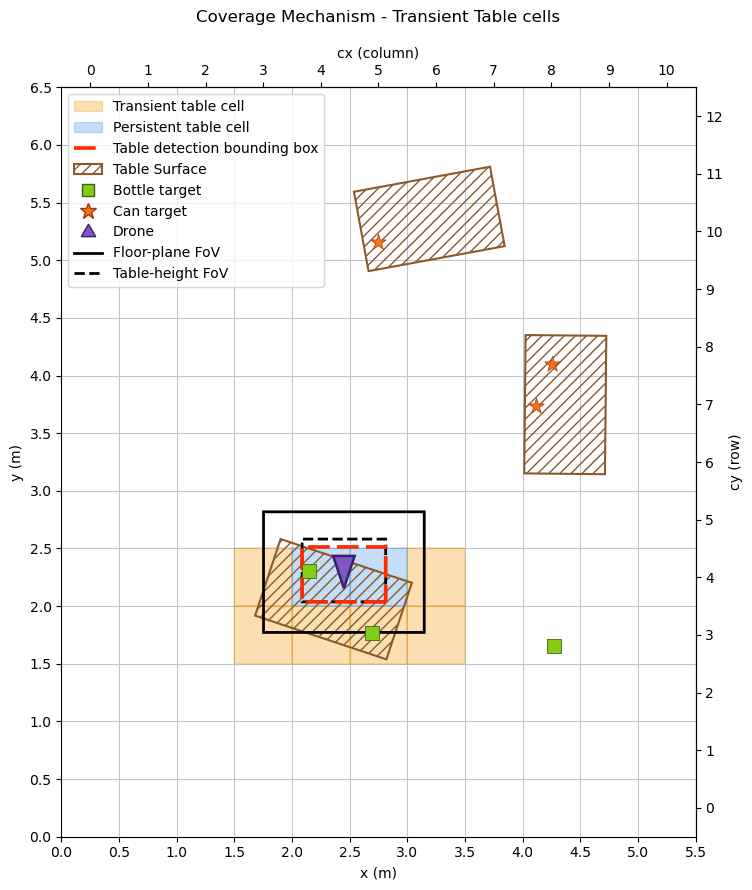

In [4]:
from pathlib import Path
import sys
import json
import math

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon, Rectangle, Patch
from matplotlib.lines import Line2D


# =============================================================================
# IMPORT THE SAME ENVIRONMENT MANAGER USED BY crazyflie_AIF.py
# =============================================================================

# This notebook runs from crazyflie_AIF/utils.
CONTROLLER_DIR = Path("..").resolve()

if str(CONTROLLER_DIR) not in sys.path:
    sys.path.insert(0, str(CONTROLLER_DIR))

from env.env_manager import GridSpec, FoVSpec, GridEnvManager


# =============================================================================
# INPUTS
# =============================================================================

JSON_PATH = Path("../../shared/spawned_objects.json")

# Room/grid configuration from crazyflie_AIF.py.
ROOM_WIDTH_M = 5.5
ROOM_HEIGHT_M = 6.5
CELL_SIZE_M = 0.5

WORLD_MIN_X = -ROOM_WIDTH_M / 2.0
WORLD_MAX_X = ROOM_WIDTH_M / 2.0
WORLD_MIN_Y = -ROOM_HEIGHT_M / 2.0
WORLD_MAX_Y = ROOM_HEIGHT_M / 2.0

GRID_COLS = int(ROOM_WIDTH_M / CELL_SIZE_M)   # 11
GRID_ROWS = int(ROOM_HEIGHT_M / CELL_SIZE_M)  # 13


# -----------------------------------------------------------------------------
# Drone pose in Webots/controller world coordinates.
# -----------------------------------------------------------------------------

DRONE_X = -0.300
DRONE_Y = -0.925
DRONE_YAW_RAD = -1.5708


# -----------------------------------------------------------------------------
# Hypothetical or logged desk detection bbox in camera pixels:
# [x1, y1, x2, y2]
#
# Keep this as the last wide-bbox example for checking the front-only gate.
# -----------------------------------------------------------------------------

CAMERA_WIDTH_PX = 320
CAMERA_HEIGHT_PX = 240

DESK_BBOX_XYXY = [0, 0, 320, 210]

CURRENT_DESK_CONFIDENCE = 1.0
SURFACE_DETECTION_CONF_THRESHOLD = 0.30

TABLE_SHADOW_FORWARD_TOLERANCE_M = 0.10


# -----------------------------------------------------------------------------
# Optional persistent table cells from earlier perception frames.
#
# These stay blue but do not independently create new transient corrections.
# -----------------------------------------------------------------------------

PREVIOUSLY_MAPPED_TABLE_CELLS = set()

# Example:
# PREVIOUSLY_MAPPED_TABLE_CELLS = {
#     (4, 4),
#     (5, 4),
# }


# -----------------------------------------------------------------------------
# Geometry copied from crazyflie_AIF.py.
# -----------------------------------------------------------------------------

FLYING_ATTITUDE_M = 1.5
FLOOR_HEIGHT_M = 0.0
TABLE_HEIGHT_M = 0.72

FOV_WIDTH_M = 1.394
FOV_FORWARD_M = 0.553
FOV_BACKWARD_M = 0.493

ENABLE_TABLE_SHADOW_PROJECTION = True

# Must match crazyflie_AIF.py.
TABLE_SHADOW_FORWARD_TOLERANCE_M = 0.10


# -----------------------------------------------------------------------------
# Display toggles.
# -----------------------------------------------------------------------------

SHOW_GRID = True
SHOW_TABLES = True
SHOW_TARGETS = True
SHOW_DRONE = True

SHOW_FLOOR_FOV = True
SHOW_TABLE_HEIGHT_FOV = True

SHOW_DIRECT_TABLE_CELLS = True
SHOW_TRANSIENT_FLOOR_CELLS = True

SHOW_CELL_COORDINATES = False
SHOW_LEGEND = True

AXIS_MODE = "meters_primary"   # "meters_primary" or "cells_primary"

TITLE = "Coverage Mechanism - Transient Table cells"

SAVE_PATH = "env_schema_shadow_transient_cells.pdf"
# SAVE_PATH = None


# -----------------------------------------------------------------------------
# Visual style.
# -----------------------------------------------------------------------------

FIGSIZE = (8.5, 9.0)

TABLE_HATCH = "///"

TABLE_SURFACE_COLOR = "#8B5A2B"

BOTTLE_COLOR = "#84CC16"
BOTTLE_EDGE_COLOR = "#3F6212"

CAN_COLOR = "#F97316"
CAN_EDGE_COLOR = "#9A3412"

DRONE_FACE_COLOR = "#7E57C2"
DRONE_EDGE_COLOR = "#3C1E6E"

DIRECT_TABLE_CELL_COLOR = "#4C9BE8"
TRANSIENT_FLOOR_CELL_COLOR = "#F39C12"

TABLE_DETECTION_BBOX_COLOR = "#FF2A00"
TABLE_DETECTION_BBOX_LINEWIDTH = 2.6
TABLE_DETECTION_BBOX_LINESTYLE = (0, (6, 2))

DIRECT_TABLE_ALPHA = 0.32
TRANSIENT_FLOOR_ALPHA = 0.32

FOV_COLOR = "black"
FOV_LINEWIDTH = 2.0

TARGET_MARKER_SIZE = 110
DRONE_SIZE_M = 0.17

SHOW_TABLE_DETECTION_BBOX = True


# =============================================================================
# GEOMETRY HELPERS
# =============================================================================

def world_to_room_xy(x, y):
    """Centered Webots world coordinates -> room-local metres."""
    return np.array(
        [
            float(x) - WORLD_MIN_X,
            float(y) - WORLD_MIN_Y,
        ],
        dtype=float,
    )


def rotate_points(points_xy, yaw_rad):
    c = math.cos(yaw_rad)
    s = math.sin(yaw_rad)

    rotation = np.array(
        [
            [c, -s],
            [s, c],
        ],
        dtype=float,
    )

    return np.asarray(points_xy, dtype=float) @ rotation.T


def fov_corners_world(drone_x, drone_y, yaw_rad, width_m, forward_m, backward_m):
    """Asymmetric rectangular FoV matching controller geometry."""
    forward = np.array([math.cos(yaw_rad), math.sin(yaw_rad)])
    left = np.array([-math.sin(yaw_rad), math.cos(yaw_rad)])

    centre = np.array([drone_x, drone_y], dtype=float)
    half_width = float(width_m) / 2.0

    return np.array(
        [
            centre + forward_m * forward + half_width * left,
            centre + forward_m * forward - half_width * left,
            centre - backward_m * forward - half_width * left,
            centre - backward_m * forward + half_width * left,
        ],
        dtype=float,
    )


def drone_triangle_world(drone_x, drone_y, yaw_rad, size_m):
    """Triangle whose nose points in the current drone-yaw direction."""
    local = np.array(
        [
            [1.00, 0.00],
            [-0.65, 0.55],
            [-0.65, -0.55],
        ],
        dtype=float,
    ) * float(size_m)

    return rotate_points(local, yaw_rad) + np.array([drone_x, drone_y])


def table_corners_world(table_obj):
    """Oracle geometry for display only; never used for shadow projection."""
    tabletop = table_obj.get("tabletop_rect", {})

    if tabletop.get("corners_xy") is not None:
        return np.asarray(tabletop["corners_xy"], dtype=float)

    centre = np.array(
        [
            float(table_obj["x"]),
            float(table_obj["y"]),
        ],
        dtype=float,
    )

    yaw = float(table_obj.get("yaw", 0.0))
    dimensions = table_obj.get("dimensions_m", {})

    length = float(dimensions.get("length", 1.2))
    width = float(dimensions.get("width", 0.7))

    local = np.array(
        [
            [-length / 2.0, -width / 2.0],
            [ length / 2.0, -width / 2.0],
            [ length / 2.0,  width / 2.0],
            [-length / 2.0,  width / 2.0],
        ],
        dtype=float,
    )

    return rotate_points(local, yaw) + centre


def rc_to_cxcy(cell_rc):
    """GridEnvManager uses (row, col); controller/policy reports (cx, cy)."""
    if cell_rc is None:
        return None

    row, col = int(cell_rc[0]), int(cell_rc[1])
    return int(col), int(row)


def cell_center_world_from_rc(cell_rc):
    """Exact equivalent of the controller's _cell_center_xy_from_rc()."""
    row, col = int(cell_rc[0]), int(cell_rc[1])

    return (
        WORLD_MIN_X + (float(col) + 0.5) * CELL_SIZE_M,
        WORLD_MIN_Y + (float(row) + 0.5) * CELL_SIZE_M,
    )


def forward_distance_for_rc(cell_rc, drone_x, drone_y, drone_yaw):
    """
    Signed distance along the drone/camera forward direction.

    Positive = in front of drone.
    Negative = rear FoV strip.
    """
    cell_x, cell_y = cell_center_world_from_rc(cell_rc)

    dx = float(cell_x) - float(drone_x)
    dy = float(cell_y) - float(drone_y)

    return (
        dx * math.cos(float(drone_yaw))
        + dy * math.sin(float(drone_yaw))
    )


def clamp_bbox_xyxy(bbox_xyxy, img_w, img_h):
    """Same clamping behaviour used by the controller."""
    if bbox_xyxy is None or len(bbox_xyxy) != 4:
        return None

    x1, y1, x2, y2 = [float(v) for v in bbox_xyxy]

    x1 = max(0.0, min(float(img_w), x1))
    x2 = max(0.0, min(float(img_w), x2))
    y1 = max(0.0, min(float(img_h), y1))
    y2 = max(0.0, min(float(img_h), y2))

    if x2 <= x1 or y2 <= y1:
        return None

    return [x1, y1, x2, y2]


def controller_probe_bboxes(
    bbox_xyxy,
    img_w,
    img_h,
    max_samples_per_axis=5,
):
    """
    Reproduce the controller's deterministic bbox sampling:

    - 2x2 to 5x5 tiny probe bboxes;
    - one additional whole-bbox/centre projection.
    """
    bbox = clamp_bbox_xyxy(bbox_xyxy, img_w=img_w, img_h=img_h)

    if bbox is None:
        return None, []

    x1, y1, x2, y2 = bbox

    width = max(1.0, x2 - x1)
    height = max(1.0, y2 - y1)

    nx = int(
        max(
            2,
            min(
                max_samples_per_axis,
                round(width / 32.0) + 1,
            ),
        )
    )

    ny = int(
        max(
            2,
            min(
                max_samples_per_axis,
                round(height / 32.0) + 1,
            ),
        )
    )

    probe_bboxes = []

    for ix in range(nx):
        px = x1 + ((ix + 0.5) / float(nx)) * width

        for iy in range(ny):
            py = y1 + ((iy + 0.5) / float(ny)) * height

            probe_bboxes.append(
                [
                    px - 0.5,
                    py - 0.5,
                    px + 0.5,
                    py + 0.5,
                ]
            )

    # Controller also projects the full bbox once.
    probe_bboxes.append(bbox)

    return bbox, probe_bboxes


def project_bbox_with_front_only_gate(
    env_mgr_table,
    env_mgr_floor,
    *,
    bbox_xyxy,
    img_w,
    img_h,
    drone_x,
    drone_y,
    drone_yaw,
    floor_covered_rc,
):
    """
    Exact notebook equivalent of the front-only controller shadow mechanism.

    Every bbox probe is mapped to:
      - a table-plane cell: direct/persistent table evidence;
      - a floor-plane cell: transient correction candidate.

    A floor counterpart is retained only if:
      table_forward > 0
      floor_forward > table_forward

    and it is inside the current floor coverage map.
    """
    clamped_bbox, probe_bboxes = controller_probe_bboxes(
        bbox_xyxy,
        img_w=img_w,
        img_h=img_h,
    )

    table_cells_rc = set()
    floor_counterparts_rc = set()

    diagnostics = {
        "total_probes": len(probe_bboxes),
        "valid_pairs": 0,
        "rejected_table_too_far_back": 0,
        "rejected_floor_too_far_back": 0,
        "rejected_floor_too_far_behind_table": 0,
        "rejected_not_in_floor_coverage": 0,
        "retained_pairs": 0,
    }

    if clamped_bbox is None:
        return table_cells_rc, floor_counterparts_rc, diagnostics, clamped_bbox

    for probe_bbox in probe_bboxes:
        table_rc = env_mgr_table.detection_cell_from_bbox(
            bbox_xyxy=probe_bbox,
            img_w=img_w,
            img_h=img_h,
            drone_x=drone_x,
            drone_y=drone_y,
            drone_yaw=drone_yaw,
        )

        floor_rc = env_mgr_floor.detection_cell_from_bbox(
            bbox_xyxy=probe_bbox,
            img_w=img_w,
            img_h=img_h,
            drone_x=drone_x,
            drone_y=drone_y,
            drone_yaw=drone_yaw,
        )

        if table_rc is not None:
            table_rc = (int(table_rc[0]), int(table_rc[1]))
            table_cells_rc.add(table_rc)

        if table_rc is None or floor_rc is None:
            continue

        floor_rc = (int(floor_rc[0]), int(floor_rc[1]))
        diagnostics["valid_pairs"] += 1

        table_forward_m = forward_distance_for_rc(
            table_rc,
            drone_x,
            drone_y,
            drone_yaw,
        )

        floor_forward_m = forward_distance_for_rc(
            floor_rc,
            drone_x,
            drone_y,
            drone_yaw,
        )

        if table_forward_m < -TABLE_SHADOW_FORWARD_TOLERANCE_M:
            diagnostics["rejected_table_too_far_back"] += 1
            continue

        if floor_forward_m < -TABLE_SHADOW_FORWARD_TOLERANCE_M:
            diagnostics["rejected_floor_too_far_back"] += 1
            continue

        if floor_forward_m < (
            table_forward_m - TABLE_SHADOW_FORWARD_TOLERANCE_M
        ):
            diagnostics["rejected_floor_too_far_behind_table"] += 1
            continue

        if floor_rc not in floor_covered_rc:
            diagnostics["rejected_not_in_floor_coverage"] += 1
            continue

        floor_counterparts_rc.add(floor_rc)
        diagnostics["retained_pairs"] += 1

    return table_cells_rc, floor_counterparts_rc, diagnostics, clamped_bbox


def configure_axes(ax):
    ax.set_xlim(0.0, ROOM_WIDTH_M)
    ax.set_ylim(0.0, ROOM_HEIGHT_M)
    ax.set_aspect("equal", adjustable="box")

    metre_ticks_x = np.arange(0.0, ROOM_WIDTH_M + 1e-9, CELL_SIZE_M)
    metre_ticks_y = np.arange(0.0, ROOM_HEIGHT_M + 1e-9, CELL_SIZE_M)

    if AXIS_MODE == "meters_primary":
        ax.set_xticks(metre_ticks_x)
        ax.set_yticks(metre_ticks_y)

        ax.set_xlabel("x (m)")
        ax.set_ylabel("y (m)")

        def metres_to_cells(value):
            return np.asarray(value) / CELL_SIZE_M - 0.5

        def cells_to_metres(value):
            return (np.asarray(value) + 0.5) * CELL_SIZE_M

        top = ax.secondary_xaxis(
            "top",
            functions=(metres_to_cells, cells_to_metres),
        )

        right = ax.secondary_yaxis(
            "right",
            functions=(metres_to_cells, cells_to_metres),
        )

        top.set_xticks(np.arange(GRID_COLS))
        right.set_yticks(np.arange(GRID_ROWS))

        top.set_xlabel("cx (column)")
        right.set_ylabel("cy (row)")

    elif AXIS_MODE == "cells_primary":
        x_centres = (np.arange(GRID_COLS) + 0.5) * CELL_SIZE_M
        y_centres = (np.arange(GRID_ROWS) + 0.5) * CELL_SIZE_M

        ax.set_xticks(x_centres)
        ax.set_yticks(y_centres)

        ax.set_xticklabels(np.arange(GRID_COLS))
        ax.set_yticklabels(np.arange(GRID_ROWS))

        ax.set_xlabel("cx (column)")
        ax.set_ylabel("cy (row)")

    else:
        raise ValueError(
            "AXIS_MODE must be 'meters_primary' or 'cells_primary'."
        )


def draw_cell_set(ax, cells, *, color, alpha, label):
    """Highlight whole grid cells without covering table hatching."""
    for index, (cx, cy) in enumerate(
        sorted(cells, key=lambda item: (item[1], item[0]))
    ):
        ax.add_patch(
            Rectangle(
                (int(cx) * CELL_SIZE_M, int(cy) * CELL_SIZE_M),
                CELL_SIZE_M,
                CELL_SIZE_M,
                facecolor=color,
                edgecolor=color,
                linewidth=1.1,
                alpha=alpha,
                label=label if index == 0 else "_nolegend_",
                zorder=2,
            )
        )

        if SHOW_CELL_COORDINATES:
            ax.text(
                (int(cx) + 0.5) * CELL_SIZE_M,
                (int(cy) + 0.5) * CELL_SIZE_M,
                f"({cx},{cy})",
                ha="center",
                va="center",
                fontsize=7,
                zorder=10,
            )


def pixel_to_table_plane_world(px, py):
    """
    Project one image pixel to the table-height plane.

    This is continuous geometry for visualisation only. The controller still
    maps sampled bbox pixels to discrete grid cells through GridEnvManager.
    """
    u = float(px) / float(CAMERA_WIDTH_PX)
    v = float(py) / float(CAMERA_HEIGHT_PX)

    table_width_m = FOV_WIDTH_M * table_scale
    table_forward_m = FOV_FORWARD_M * table_scale
    table_backward_m = FOV_BACKWARD_M * table_scale

    # Image y=0 is the forward edge of the downward camera image.
    forward_offset_m = (
        table_forward_m
        - v * (table_forward_m + table_backward_m)
    )

    # Image x=0 is the camera's left side.
    lateral_offset_m = (0.5 - u) * table_width_m

    forward_vec = np.array(
        [
            math.cos(DRONE_YAW_RAD),
            math.sin(DRONE_YAW_RAD),
        ],
        dtype=float,
    )

    left_vec = np.array(
        [
            -math.sin(DRONE_YAW_RAD),
            math.cos(DRONE_YAW_RAD),
        ],
        dtype=float,
    )

    return (
        np.array([DRONE_X, DRONE_Y], dtype=float)
        + forward_offset_m * forward_vec
        + lateral_offset_m * left_vec
    )


def draw_table_detection_bbox_projection(ax, bbox_xyxy):
    """
    Draw the current image-space desk detection bbox projected continuously
    onto the table-height plane.
    """
    bbox = clamp_bbox_xyxy(
        bbox_xyxy,
        CAMERA_WIDTH_PX,
        CAMERA_HEIGHT_PX,
    )

    if bbox is None:
        return

    x1, y1, x2, y2 = bbox

    pixel_corners = [
        (x1, y1),
        (x2, y1),
        (x2, y2),
        (x1, y2),
    ]

    projected_room_corners = np.array(
        [
            world_to_room_xy(*pixel_to_table_plane_world(px, py))
            for px, py in pixel_corners
        ]
    )

    ax.add_patch(
        Polygon(
            projected_room_corners,
            closed=True,
            fill=False,
            edgecolor=TABLE_DETECTION_BBOX_COLOR,
            linewidth=TABLE_DETECTION_BBOX_LINEWIDTH,
            linestyle=TABLE_DETECTION_BBOX_LINESTYLE,
            zorder=5.5,
        )
    )


# =============================================================================
# LOAD SPAWN MANIFEST
# =============================================================================

with JSON_PATH.open("r", encoding="utf-8") as file:
    manifest = json.load(file)

objects = manifest.get("objects", [])

tables = [
    obj for obj in objects
    if obj.get("class_name") == "desk"
]

bottles = [
    obj for obj in objects
    if obj.get("class_name") == "target_bottle"
]

cans = [
    obj for obj in objects
    if obj.get("class_name") == "target_can"
]


# =============================================================================
# BUILD THE SAME FLOOR/TABLE GRID MANAGERS AS THE CONTROLLER
# =============================================================================

grid_spec = GridSpec(
    min_x=WORLD_MIN_X,
    max_x=WORLD_MAX_X,
    min_y=WORLD_MIN_Y,
    max_y=WORLD_MAX_Y,
    cell_size=CELL_SIZE_M,
    rows=GRID_ROWS,
    cols=GRID_COLS,
)

floor_fov_spec = FoVSpec(
    half_left=FOV_WIDTH_M / 2.0,
    half_right=FOV_WIDTH_M / 2.0,
    forward=FOV_FORWARD_M,
    backward=FOV_BACKWARD_M,
)

table_scale = (
    (FLYING_ATTITUDE_M - TABLE_HEIGHT_M)
    / (FLYING_ATTITUDE_M - FLOOR_HEIGHT_M)
)

table_fov_spec = FoVSpec(
    half_left=(FOV_WIDTH_M * table_scale) / 2.0,
    half_right=(FOV_WIDTH_M * table_scale) / 2.0,
    forward=FOV_FORWARD_M * table_scale,
    backward=FOV_BACKWARD_M * table_scale,
)

env_mgr_floor = GridEnvManager(grid_spec, floor_fov_spec)
env_mgr_table = GridEnvManager(grid_spec, table_fov_spec)


# =============================================================================
# CONTROLLER-EQUIVALENT FRONT-ONLY PROJECTION
# =============================================================================

floor_coverages_rc = env_mgr_floor.compute_cell_coverages(
    DRONE_X,
    DRONE_Y,
    DRONE_YAW_RAD,
)

floor_covered_rc = {
    (int(row), int(col))
    for row, col in floor_coverages_rc.keys()
}

if (
    ENABLE_TABLE_SHADOW_PROJECTION
    and CURRENT_DESK_CONFIDENCE >= SURFACE_DETECTION_CONF_THRESHOLD
):
    (
        current_table_cells_rc,
        current_floor_counterparts_rc,
        projection_diagnostics,
        clamped_bbox,
    ) = project_bbox_with_front_only_gate(
        env_mgr_table,
        env_mgr_floor,
        bbox_xyxy=DESK_BBOX_XYXY,
        img_w=CAMERA_WIDTH_PX,
        img_h=CAMERA_HEIGHT_PX,
        drone_x=DRONE_X,
        drone_y=DRONE_Y,
        drone_yaw=DRONE_YAW_RAD,
        floor_covered_rc=floor_covered_rc,
    )

else:
    current_table_cells_rc = set()
    current_floor_counterparts_rc = set()
    clamped_bbox = clamp_bbox_xyxy(
        DESK_BBOX_XYXY,
        CAMERA_WIDTH_PX,
        CAMERA_HEIGHT_PX,
    )
    projection_diagnostics = {
        "total_probes": 0,
        "valid_pairs": 0,
        "rejected_table_not_forward": 0,
        "rejected_floor_not_further": 0,
        "rejected_not_in_floor_coverage": 0,
        "retained_pairs": 0,
    }

current_table_cells = {
    rc_to_cxcy(rc)
    for rc in current_table_cells_rc
    if rc_to_cxcy(rc) is not None
}

current_floor_counterpart_cells = {
    rc_to_cxcy(rc)
    for rc in current_floor_counterparts_rc
    if rc_to_cxcy(rc) is not None
}

persistent_table_cells = {
    (int(cx), int(cy))
    for cx, cy in PREVIOUSLY_MAPPED_TABLE_CELLS
}

direct_table_cells = (
    persistent_table_cells
    | current_table_cells
)

transient_floor_cells = (
    current_floor_counterpart_cells
    - direct_table_cells
)

effective_table_projection_cells = (
    direct_table_cells
    | current_floor_counterpart_cells
)


# =============================================================================
# IDEALIZED FOV OUTLINES
# =============================================================================

floor_fov_world = fov_corners_world(
    DRONE_X,
    DRONE_Y,
    DRONE_YAW_RAD,
    width_m=FOV_WIDTH_M,
    forward_m=FOV_FORWARD_M,
    backward_m=FOV_BACKWARD_M,
)

table_fov_world = fov_corners_world(
    DRONE_X,
    DRONE_Y,
    DRONE_YAW_RAD,
    width_m=FOV_WIDTH_M * table_scale,
    forward_m=FOV_FORWARD_M * table_scale,
    backward_m=FOV_BACKWARD_M * table_scale,
)


# =============================================================================
# DRAW
# =============================================================================

fig, ax = plt.subplots(figsize=FIGSIZE)

configure_axes(ax)

if SHOW_GRID:
    for x in np.arange(0.0, ROOM_WIDTH_M + 1e-9, CELL_SIZE_M):
        ax.axvline(
            x,
            color="#B8C4CF",
            linewidth=0.75,
            zorder=0,
        )

    for y in np.arange(0.0, ROOM_HEIGHT_M + 1e-9, CELL_SIZE_M):
        ax.axhline(
            y,
            color="#B8C4CF",
            linewidth=0.75,
            zorder=0,
        )

# Draw transient corrections first.
if SHOW_TRANSIENT_FLOOR_CELLS:
    draw_cell_set(
        ax,
        transient_floor_cells,
        color=TRANSIENT_FLOOR_CELL_COLOR,
        alpha=TRANSIENT_FLOOR_ALPHA,
        label="Transient table cell",
    )

if SHOW_DIRECT_TABLE_CELLS:
    draw_cell_set(
        ax,
        direct_table_cells,
        color=DIRECT_TABLE_CELL_COLOR,
        alpha=DIRECT_TABLE_ALPHA,
        label="Persistent table cell",
    )

# Oracle tabletop geometry is visual context only.
if SHOW_TABLES:
    for table in tables:
        tabletop_room = np.array(
            [
                world_to_room_xy(x, y)
                for x, y in table_corners_world(table)
            ]
        )

        ax.add_patch(
            Polygon(
                tabletop_room,
                closed=True,
                facecolor="none",
                edgecolor=TABLE_SURFACE_COLOR,
                hatch=TABLE_HATCH,
                linewidth=1.5,
                zorder=4,
            )
        )


if SHOW_TARGETS and bottles:
    bottle_xy = np.array(
        [
            world_to_room_xy(obj["x"], obj["y"])
            for obj in bottles
        ]
    )

    ax.scatter(
        bottle_xy[:, 0],
        bottle_xy[:, 1],
        marker="s",
        s=TARGET_MARKER_SIZE,
        color=BOTTLE_COLOR,
        edgecolors=BOTTLE_EDGE_COLOR,
        linewidths=0.6,
        zorder=6,
    )

if SHOW_TARGETS and cans:
    can_xy = np.array(
        [
            world_to_room_xy(obj["x"], obj["y"])
            for obj in cans
        ]
    )

    ax.scatter(
        can_xy[:, 0],
        can_xy[:, 1],
        marker="*",
        s=TARGET_MARKER_SIZE * 1.25,
        color=CAN_COLOR,
        edgecolors=CAN_EDGE_COLOR,
        linewidths=0.5,
        zorder=6,
    )

if SHOW_DRONE:
    drone_room = np.array(
        [
            world_to_room_xy(x, y)
            for x, y in drone_triangle_world(
                DRONE_X,
                DRONE_Y,
                DRONE_YAW_RAD,
                DRONE_SIZE_M,
            )
        ]
    )

    ax.add_patch(
        Polygon(
            drone_room,
            closed=True,
            facecolor=DRONE_FACE_COLOR,
            edgecolor=DRONE_EDGE_COLOR,
            linewidth=1.8,
            zorder=8,
        )
    )

if SHOW_FLOOR_FOV:
    floor_fov_room = np.array(
        [
            world_to_room_xy(x, y)
            for x, y in floor_fov_world
        ]
    )

    ax.add_patch(
        Polygon(
            floor_fov_room,
            closed=True,
            fill=False,
            edgecolor=FOV_COLOR,
            linewidth=FOV_LINEWIDTH,
            label="Floor-plane FoV",
            zorder=5,
        )
    )

if SHOW_TABLE_HEIGHT_FOV:
    table_fov_room = np.array(
        [
            world_to_room_xy(x, y)
            for x, y in table_fov_world
        ]
    )

    ax.add_patch(
        Polygon(
            table_fov_room,
            closed=True,
            fill=False,
            edgecolor=FOV_COLOR,
            linewidth=FOV_LINEWIDTH,
            linestyle="--",
            label="Table-height FoV",
            zorder=5,
        )
    )

ax.set_title(TITLE, pad=18)

if SHOW_TABLE_DETECTION_BBOX:
    draw_table_detection_bbox_projection(
        ax,
        DESK_BBOX_XYXY,
    )

if SHOW_LEGEND:
    legend_handles = []

    if SHOW_TRANSIENT_FLOOR_CELLS and transient_floor_cells:
        legend_handles.append(
            Patch(
                facecolor=TRANSIENT_FLOOR_CELL_COLOR,
                edgecolor=TRANSIENT_FLOOR_CELL_COLOR,
                alpha=TRANSIENT_FLOOR_ALPHA,
                label="Transient table cell",
            )
        )

    if SHOW_DIRECT_TABLE_CELLS and direct_table_cells:
        legend_handles.append(
            Patch(
                facecolor=DIRECT_TABLE_CELL_COLOR,
                edgecolor=DIRECT_TABLE_CELL_COLOR,
                alpha=DIRECT_TABLE_ALPHA,
                label="Persistent table cell",
            )
        )

    if SHOW_TABLE_DETECTION_BBOX and current_table_cells:
        legend_handles.append(
            Line2D(
                [0],
                [0],
                color=TABLE_DETECTION_BBOX_COLOR,
                linewidth=TABLE_DETECTION_BBOX_LINEWIDTH,
                linestyle=TABLE_DETECTION_BBOX_LINESTYLE,
                label="Table detection bounding box",
            )
        )

    if SHOW_TABLES and tables:
        legend_handles.append(
            Patch(
                facecolor="white",
                edgecolor=TABLE_SURFACE_COLOR,
                hatch=TABLE_HATCH,
                linewidth=1.5,
                label="Table Surface",
            )
        )

    if SHOW_TARGETS and bottles:
        legend_handles.append(
            Line2D(
                [0],
                [0],
                marker="s",
                linestyle="None",
                markersize=9,
                markerfacecolor=BOTTLE_COLOR,
                markeredgecolor=BOTTLE_EDGE_COLOR,
                label="Bottle target",
            )
        )

    if SHOW_TARGETS and cans:
        legend_handles.append(
            Line2D(
                [0],
                [0],
                marker="*",
                linestyle="None",
                markersize=12,
                markerfacecolor=CAN_COLOR,
                markeredgecolor=CAN_EDGE_COLOR,
                label="Can target",
            )
        )

    if SHOW_DRONE:
        legend_handles.append(
            Line2D(
                [0],
                [0],
                marker=(3, 0, 0),
                linestyle="None",
                markersize=12,
                markerfacecolor=DRONE_FACE_COLOR,
                markeredgecolor=DRONE_EDGE_COLOR,
                label="Drone",
            )
        )

    if SHOW_FLOOR_FOV:
        legend_handles.append(
            Line2D(
                [0],
                [0],
                color=FOV_COLOR,
                linewidth=FOV_LINEWIDTH,
                label="Floor-plane FoV",
            )
        )

    if SHOW_TABLE_HEIGHT_FOV:
        legend_handles.append(
            Line2D(
                [0],
                [0],
                color=FOV_COLOR,
                linewidth=FOV_LINEWIDTH,
                linestyle="--",
                label="Table-height FoV",
            )
        )

    ax.legend(
        handles=legend_handles,
        loc="upper left",
        frameon=True,
    )

fig.tight_layout()

print(f"Input bbox: {clamped_bbox}")

print("\nProjection diagnostics:")
for key, value in projection_diagnostics.items():
    print(f"  {key}: {value}")

print("\nCurrent table-plane bbox cells (blue):")
print(sorted(current_table_cells, key=lambda cell: (cell[1], cell[0])))

print("\nFront-only retained floor counterparts:")
print(sorted(current_floor_counterpart_cells, key=lambda cell: (cell[1], cell[0])))

print("\nTransient floor counterparts only (orange):")
print(sorted(transient_floor_cells, key=lambda cell: (cell[1], cell[0])))

print("\nEffective table-height coverage cells this frame:")
print(sorted(effective_table_projection_cells, key=lambda cell: (cell[1], cell[0])))

for cx, cy in [(3, 4), (6, 4)]:
    rc = (cy, cx)

    print(
        f"cell ({cx},{cy}) "
        f"forward={forward_distance_for_rc(rc, DRONE_X, DRONE_Y, DRONE_YAW_RAD):.3f} m "
        f"transient={((cx, cy) in transient_floor_cells)} "
        f"direct={((cx, cy) in direct_table_cells)}"
    )

    
if SAVE_PATH is not None:
    SAVE_PATH = Path(SAVE_PATH)
    SAVE_PATH.parent.mkdir(parents=True, exist_ok=True)

    fig.savefig(
        SAVE_PATH,
        bbox_inches="tight",
    )

plt.show()